In [1]:
from collections import Counter
import itertools
import json
import geopandas as gpd
from glob import glob
import math
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kendalltau
import seaborn as sns
import os

In [2]:
acc_cols = ['gravity_BEDS', '2sfca_30_BEDS', '2sfca_60_BEDS', 'e2sfca_30_BEDS', 'e2sfca_60_BEDS',
            'g2sfca10_BEDS', 'g2sfca20_BEDS', '3sfca_BEDS', 'raam30_BEDS', 'raam60_BEDS']
acc_titles = {
    'gravity_BEDS': "Gravity",
    '2sfca_30_BEDS': "2SFCA (30min)",
    '2sfca_60_BEDS': "2SFCA (60min)",
    'e2sfca_30_BEDS': "E2SFCA (30min)",
    'e2sfca_60_BEDS': "E2SFCA (60 min)",
    'g2sfca10_BEDS': r"G2SFCA ($\sigma$=10)",
    'g2sfca20_BEDS': r"G2SFCA ($\sigma$=20)",
    '3sfca_BEDS': "3SFCA",
    'raam30_BEDS': r"RAAM ($\tau$=30)",
    'raam60_BEDS': r"RAAM ($\tau$=60)"
}

In [3]:
acc_corr = "raam60_BEDS"
# acc_corr = "gravity_BEDS"
res_col = "Cost_2"

In [4]:
# load the hospitals
hos = gpd.read_file("../data/hospitals/ContinentalHospitals.shp")
hos = hos[(hos["STATE"] == "IL") & (hos["COUNTY"] == "COOK")]
hos = hos[hos["BEDS"] >= 0]
hos = hos.to_crs("EPSG:4326")
print(len(hos), sum(hos["BEDS"]))
hos.head()

66 18259


,OBJECTID,ID,NAME,ADDRESS,CITY,STATE,ZIP,ZIP4,TELEPHONE,TYPE,...,WEBSITE,STATE_ID,ALT_NAME,ST_FIPS,OWNER,TTL_STAFF,BEDS,TRAUMA,HELIPAD,geometry
507,1513,0003460644,UHS HARTGROVE HOSPITAL,5730 WEST ROOSEVELT ROAD,CHICAGO,IL,60644,NOT AVAILABLE,(773) 413-1700,PSYCHIATRIC,...,http://www.hartgrovehospital.com,0005454,NOT AVAILABLE,17,PROPRIETARY,-999,128,NOT AVAILABLE,N,POINT (-87.76746 41.86633)
508,1514,0001860612,JESSE BROWN VA MEDICAL CENTER - VA CHICAGO HEA...,820 S DAMEN STREET,CHICAGO,IL,60612,NOT AVAILABLE,(312) 569-8387,MILITARY,...,http://www.chicago.va.gov/,14003F,NOT AVAILABLE,17,GOVERNMENT - FEDERAL,-999,240,NOT AVAILABLE,N,POINT (-87.67704 41.87074)
509,1515,0003160463,PALOS COMMUNITY HOSPITAL,12251 SOUTH 80TH AVENUE,PALOS HEIGHTS,IL,60464,NOT AVAILABLE,(708) 923-4000,GENERAL ACUTE CARE,...,http://www.paloscommunityhospital.org,140062,NOT AVAILABLE,17,NON-PROFIT,-999,377,NOT AVAILABLE,Y,POINT (-87.81344 41.66921)
510,1516,0003660628,ROSELAND COMMUNITY HOSPITAL,45 W 111TH STREET,CHICAGO,IL,60628,NOT AVAILABLE,(773) 995-3000,GENERAL ACUTE CARE,...,http://www.roselandhospital.org,140068,NOT AVAILABLE,17,NON-PROFIT,-999,115,NOT AVAILABLE,N,POINT (-87.62536 41.69223)
511,1517,0002360302,WEST SUBURBAN MEDICAL CENTER,3 ERIE COURT,OAK PARK,IL,60302,NOT AVAILABLE,(708) 383-6200,GENERAL ACUTE CARE,...,http://www.westsuburbanmc.com/Home.aspx,140049,NOT AVAILABLE,17,PROPRIETARY,-999,172,NOT AVAILABLE,N,POINT (-87.77618 41.8914)


In [5]:
acc = gpd.read_file("../data/accessibility/CookHospitals.gpkg")
acc = acc.set_index("geoid")
cols = list(acc.columns)
cols.remove('geometry')
# acc = normalize_columns(acc, cols)
# drop rows with nan values
acc = acc.dropna(subset=[acc_corr])
print(len(acc))
acc.head()

1315


,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry
geoid,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019..."
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019..."
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012..."
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.6634 42.0150..."
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009..."


In [6]:
experiment_paths_nv = glob("../outputs/NoVeh/*")
experiment_paths_oc = glob("../outputs/OnlyCars/*")
# print(len(experiment_paths))
experiment_paths = {'noveh': experiment_paths_nv, 'onlycars': experiment_paths_oc}
# experiment_paths = {'onlycars': experiment_paths_oc}

In [7]:
# params tested
cost_funcs = ["raam", "gravity"]
noveh = ['onlycars', 'noveh']
timesteps = [10, 15, 20, 25, 30]
topK = [1, 2, 3, 4, 5]
numAgents = [1000, 100, 10, 1]

In [8]:
# quick sanity check
cf_counter, ts_counter, tk_counter, na_counter = Counter(), Counter(), Counter(), Counter()
for k, v in experiment_paths.items():
    for path in v:
        # print(path)
        # load the parameter json
        param_path = os.path.join(path, "parameters.json")
        param_file = open(param_path)
        params = json.load(param_file)
        cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
    #     print(cf, ts, tk, na)
        cf_counter[cf] +=1
        ts_counter[ts] +=1
        tk_counter[tk] +=1
        na_counter[na] +=1
# you should see even numbers for all parameter options
cf_counter, ts_counter, tk_counter, na_counter

(Counter({'gravity': 1000, 'raam': 1000}),
 Counter({30: 400, 25: 400, 20: 400, 15: 400, 10: 400}),
 Counter({5: 400, 4: 400, 3: 400, 1: 400, 2: 400}),
 Counter({100: 500, 1: 500, 10: 500, 1000: 500}))

In [9]:
def calculate_corrs(acc_corr, res_col):
    experiment_corr = dict()
    for k, v in experiment_paths.items():
        for path in v:
            # load the parameter json
            param_path = os.path.join(path, "parameters.json")
            param_file = open(param_path)
            params = json.load(param_file)
            cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
            # load the data
            results = pd.read_csv(os.path.join(path, "spatial_units.csv"), index_col="GEOID")
            results.index = results.index.map(str)
            # join with accessibility data on GEOID
            # join the last time step's cost
            merged = pd.merge(acc[[acc_corr]], results[[res_col]], left_index=True, right_index=True)
        #     print(len(merged))
            corr_res = kendalltau(merged[acc_corr], merged[res_col])
            if acc_corr in ["raam_BEDS"]:
                _correlation = corr_res.correlation
            else:
                _correlation = -corr_res.correlation  # negate from access to cost
            try:
                experiment_corr[k, cf, ts, tk, na].append(_correlation)
            except:
                experiment_corr[k, cf, ts, tk, na] = [_correlation]
    return experiment_corr

In [10]:
experiment_corr = calculate_corrs(acc_corr, res_col)
experiment_corr

{('noveh', 'gravity', 30, 5, 100): [np.float64(-0.7002436469492045),
  np.float64(-0.7061745114039504),
  np.float64(-0.7040841247518679),
  np.float64(-0.7010955431706511),
  np.float64(-0.7040887546226364)],
 ('noveh', 'gravity', 25, 4, 1): [np.float64(-0.7179181786088394),
  np.float64(-0.7182862533349538),
  np.float64(-0.7178093766457743),
  np.float64(-0.7178718799011522),
  np.float64(-0.7172537921535265)],
 ('noveh', 'raam', 25, 4, 10): [np.float64(-0.8014479920829208),
  np.float64(-0.8032166027165766),
  np.float64(-0.8014595667598428),
  np.float64(-0.8016632810736669),
  np.float64(-0.8012766868644778)],
 ('noveh', 'gravity', 20, 3, 1000): [np.float64(-0.6452986556012754),
  np.float64(-0.6471043052010811),
  np.float64(-0.635754177011534),
  np.float64(-0.6368954401560265),
  np.float64(-0.6440786846537145)],
 ('noveh', 'raam', 15, 1, 10): [np.float64(-0.8405333611125578),
  np.float64(-0.8356326429038549),
  np.float64(-0.8373433801529013),
  np.float64(-0.836567876799138

In [11]:
std_devs = []
for key, val in experiment_corr.items():
    std_devs.append(np.std(val))

(array([246.,  67.,  34.,  14.,  13.,  11.,   6.,   7.,   1.,   1.]),
 array([0.        , 0.00105817, 0.00211634, 0.00317452, 0.00423269,
        0.00529086, 0.00634903, 0.00740721, 0.00846538, 0.00952355,
        0.01058172]),
 <BarContainer object of 10 artists>)

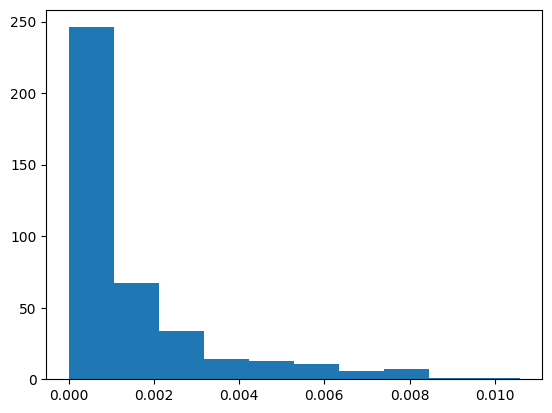

In [12]:
plt.hist(std_devs)

In [13]:
def get_ylims(ecorr):
    corrs = {'raam': [], 'gravity': []}
    for k, v in ecorr.items():
        corrs[k[1]].extend(v)
    _min = math.floor(min([min(corrs['raam']), min(corrs['gravity'])])*10)/10.0
    _max = math.ceil(max([max(corrs['raam']), max(corrs['gravity'])])*10)/10.0
    return(_min, _max)

In [14]:
print(get_ylims(experiment_corr))

(-0.9, -0.5)


In [15]:
def parameter_boxplots(experiment_corr, save_path):
    fig, axes = plt.subplots(4, 3, figsize=(14, 12))
    ylims = get_ylims(experiment_corr)
    colors = [
        ["#6267f5", "#6cf562"],
        ["#f56462", "#f5a462"]
    ]

    fsize = 20
    for i, cf in enumerate(cost_funcs):
        for j, nv in enumerate(noveh):
            # get the ax for numAgents
            ax = axes[i*2 + j, 0]
            parameters = numAgents
            oparameters = (timesteps, topK)
            vals = dict()
            for p in parameters:
                vals[p] = list()
                for a, b in itertools.product(*oparameters):
                    vals[p].extend(experiment_corr[nv, cf, a, b, p])
            x_labels = [str(x) for x in parameters]
            data = [vals[p] for p in parameters]
            ax.boxplot(data, tick_labels=x_labels)
    #         ax.set_title("Correlations by PopPerAgent")
            ax.set_ylim(*ylims)
#             if not (i == 1 and j == 1):
#                 ax.set_xticklabels([])
            # get the ax for topk
            ax = axes[i*2 + j, 1]
            parameters = topK
            oparameters = (timesteps, numAgents)
            vals = dict()
            for p in parameters:
                vals[p] = list()
                for a, b in itertools.product(*oparameters):
                    vals[p].extend(experiment_corr[nv, cf, a, p, b])
            x_labels = [str(x) for x in parameters]
            data = [vals[p] for p in parameters]
            ax.boxplot(data, tick_labels=x_labels)
#             if not (i == 1 and j == 1):
#                 ax.set_xticklabels([])
            ax.set_yticklabels([])
    #         ax.set_title("Correlations by topK")
            ax.set_ylim(*ylims)
            # get the ax for timesteps
            ax = axes[i*2 + j, 2]
            parameters = timesteps
            oparameters = (topK, numAgents)
            vals = dict()
            for p in parameters:
                vals[p] = list()
                for a, b in itertools.product(*oparameters):
                    vals[p].extend(experiment_corr[nv, cf, p, a, b])
            x_labels = [str(x) for x in parameters]
            data = [vals[p] for p in parameters]
            ax.boxplot(data, tick_labels=x_labels)
    #         ax.set_title("Correlations by Time Steps")
            ax.set_ylim(*ylims)
#             if not (i == 1 and j == 1):
#                 ax.set_xticklabels([])
            ax.set_yticklabels([])

    for ax in axes.flatten():
        ax.tick_params(axis='both', which='major', labelsize=fsize-4)
        ax.grid('on')

    clabels = ["PopPerAgent", "topK", "Time Steps"]
    for ax, clab in zip(axes[0], clabels):
        ax.set_title(clab, fontsize=fsize)
    rlabels = ["RAAM, Cars", "RAAM, NoVeh", "Gravity, Cars", "Gravity, NoVeh"]
    for ax, lab in zip(axes[:, 0], rlabels):
        ax.set_ylabel(lab, fontsize=fsize)

    spacer = "     "
    fig.supylabel(f"Correlations between Model Results and Traditional {acc_titles[acc_corr]} Method", fontsize=20)
    # fig.supxlabel(f"Distribution of Correlations by Parameter", fontsize=24)

    plt.subplots_adjust(wspace=0, hspace=0)
    fig.tight_layout()
    plt.savefig(save_path, dpi=400)
    plt.show()

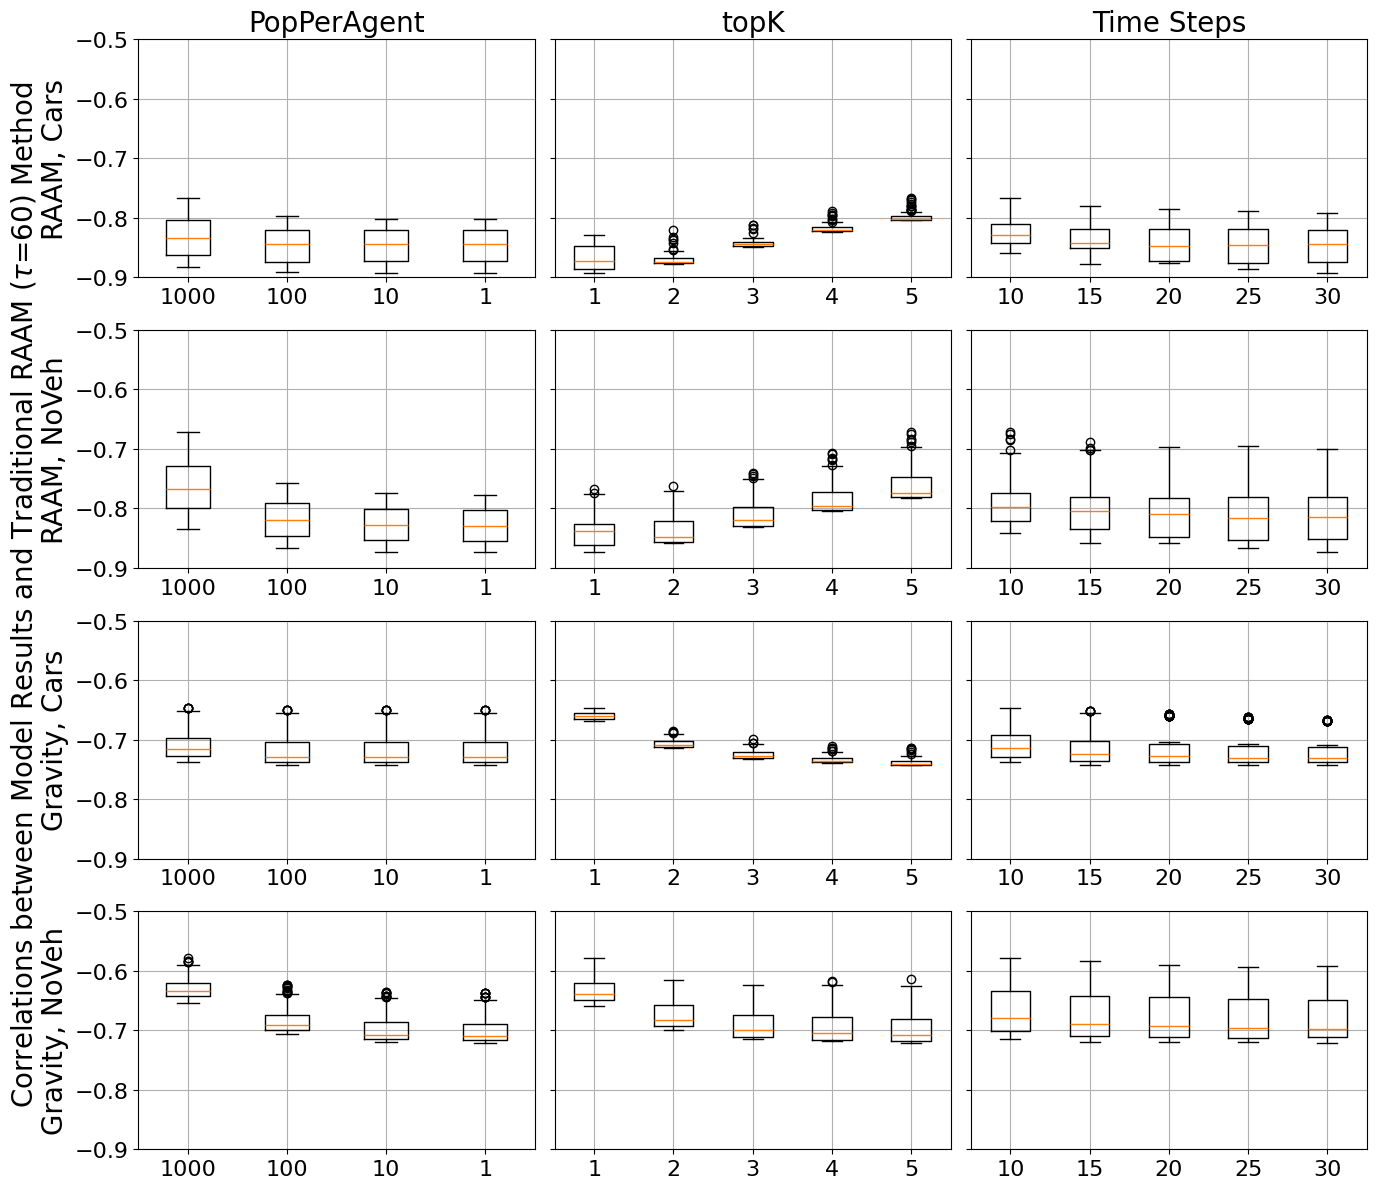

In [16]:
# for acc_col in cols:
# for acc_col in ['raam60_BEDS']:
#     print(acc_col)
#     experiment_corr = calculate_corrs(acc_col, res_col)
parameter_boxplots(experiment_corr,f"../figs/CorrelationsByParameter{acc_corr}.png")

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry
geoid,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019..."
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019..."
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012..."
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.6634 42.0150..."
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009..."


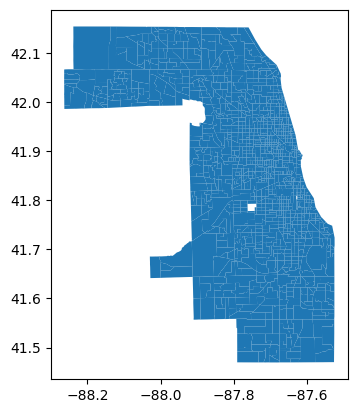

In [17]:
mean_costs = acc.copy(deep=True)
mean_costs.plot()
mean_costs.head()

In [18]:
mean_costs_raam = acc.copy(deep=True)
cost_dict = {x: [] for x in mean_costs.index}
for k, v in experiment_paths.items():
    for path in v:
        # load the parameter json
        param_path = os.path.join(path, "parameters.json")
        param_file = open(param_path)
        params = json.load(param_file)
        cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
        if cf == "raam":
            # load the data
            results = pd.read_csv(os.path.join(path, "spatial_units.csv"), index_col="GEOID")
            results.index = results.index.map(str)
            for index, row in results.iterrows():
                try:
                    cost_dict[index].append(row[res_col])
                except:
                    cost_dict[index] = []
                    cost_dict[index].append(row[res_col])
                    

In [19]:
# cost_dict

In [20]:
avg_costs = {key: np.mean(val) for key, val in cost_dict.items()}

In [21]:
avg_cost_df = pd.DataFrame.from_dict(avg_costs, orient='index', columns=['avgCost'])
avg_cost_df.head()

,avgCost
17031010100,1.422924
17031010201,1.366006
17031010202,1.429753
17031010300,1.464803
17031010400,1.484159


In [22]:
merged = acc.merge(avg_cost_df, left_index=True, right_index=True)
merged.head()

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry,avgCost
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019...",1.422924
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019...",1.366006
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012...",1.429753
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.6634 42.0150...",1.464803
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009...",1.484159


<Axes: >

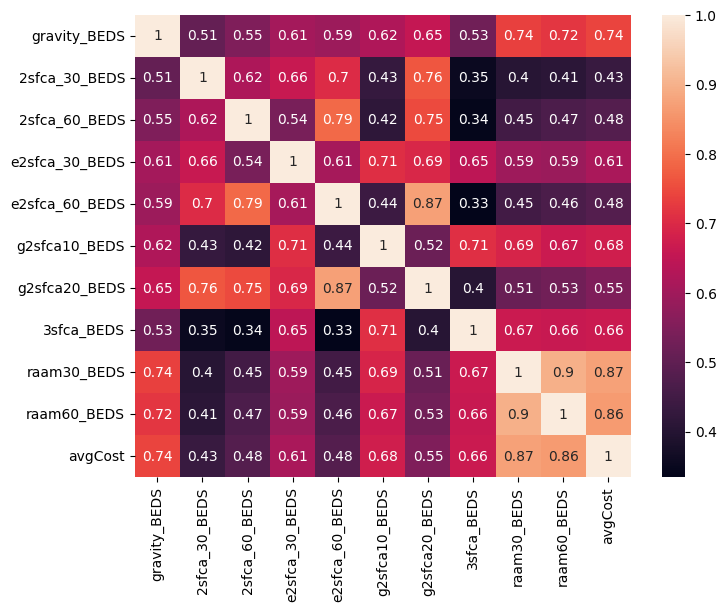

In [23]:
tmp = merged.drop(columns=["geometry"])
to_negate = ['raam30_BEDS', 'raam60_BEDS', 'avgCost']
for col in to_negate:
    tmp[col] = - tmp[col]
corr = tmp.corr(method='kendall')
fig, ax = plt.subplots(figsize=(8, 6))  
sns.heatmap(corr, annot=True, ax=ax)

/tmp/ipykernel_411983/1132745689.py:1: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([merged[acc_corr], merged["avgCost"]], labels=[acc_corr, "AgentAccess"])


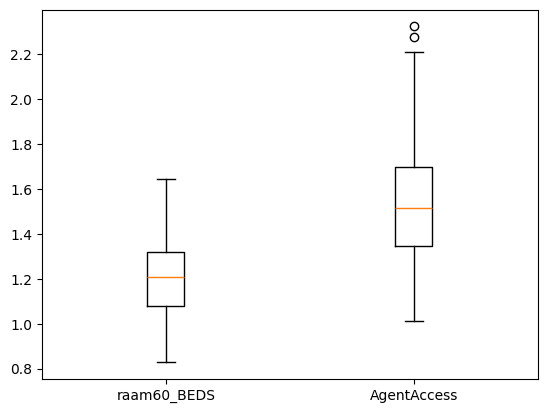

In [24]:
plt.boxplot([merged[acc_corr], merged["avgCost"]], labels=[acc_corr, "AgentAccess"])
# plt.hist(merged[acc_corr], alpha=0.5, label=acc_corr)
# plt.hist(merged["avgCost"], alpha=0.5, label="AgentAccess")
# plt.legend(loc='upper right')
plt.show()

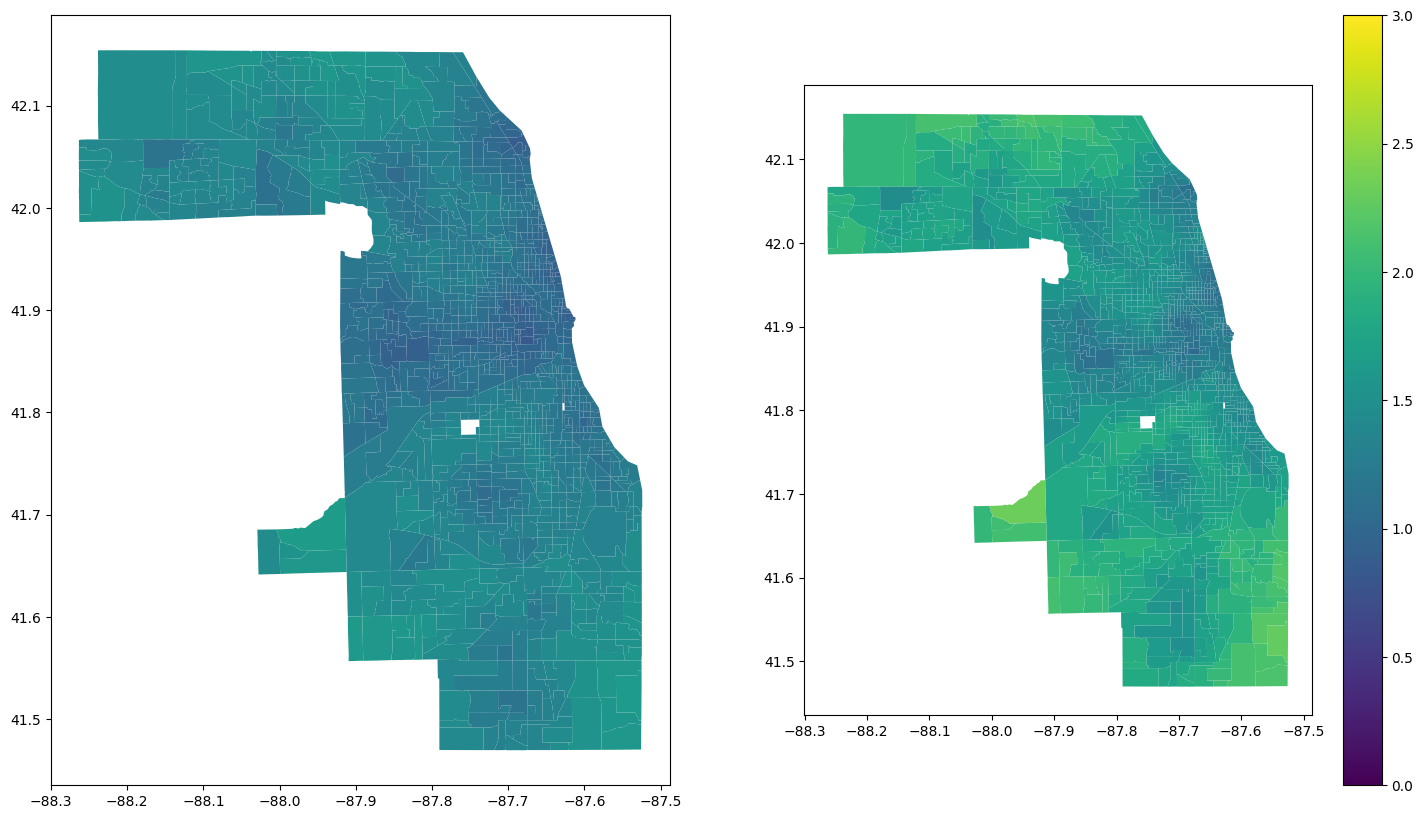

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(18, 10))
merged.plot(ax=axes[0], column=acc_corr, vmin=0, vmax=3)
merged.plot(ax=axes[1], column="avgCost", vmin=0, vmax=3, legend=True)
plt.show()

<Axes: >

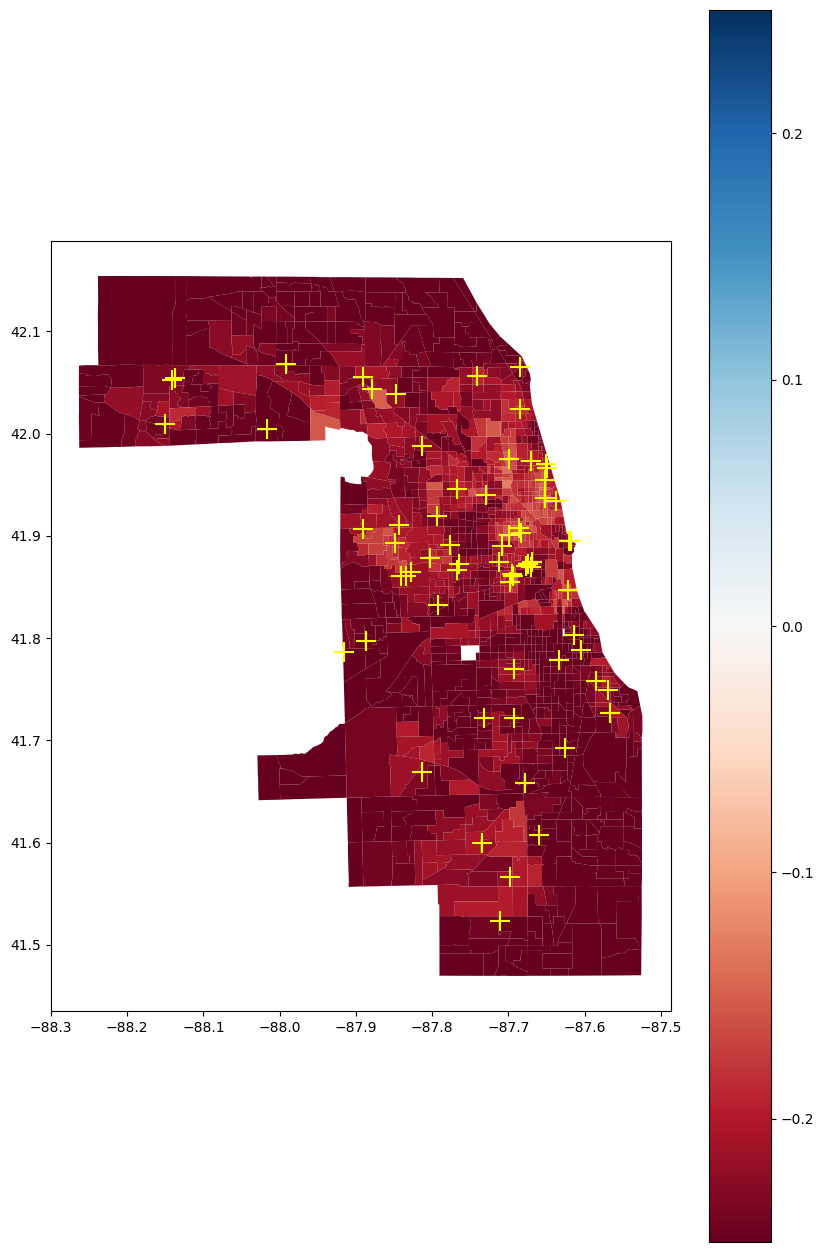

In [26]:
merged["diff"] = (merged[acc_corr] - merged['avgCost']) / ((merged[acc_corr] + merged['avgCost']) / 2.0)
ax = merged.plot(column='diff', figsize=(10, 16), legend=True, cmap="RdBu", vmin=-.25, vmax=.25)
hos.plot(ax=ax, color='yellow', marker='+', markersize=200)
# merged.head()

# Mean costs by top k

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry
geoid,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019..."
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019..."
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012..."
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.6634 42.0150..."
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009..."


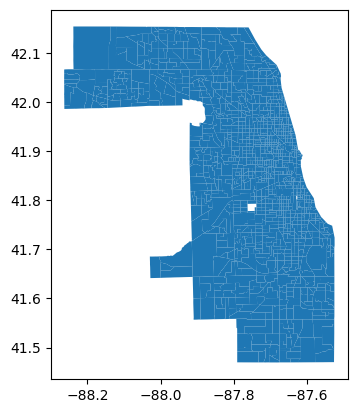

In [27]:
mean_costs_byk = acc.copy(deep=True)
mean_costs_byk.plot()
mean_costs_byk.head()

In [28]:
cost_dict = {x: dict() for x in mean_costs.index}
for k, v in experiment_paths.items():
    for path in v:
        # load the parameter json
        param_path = os.path.join(path, "parameters.json")
        param_file = open(param_path)
        params = json.load(param_file)
        cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
        if cf == "raam":
            # load the data
            results = pd.read_csv(os.path.join(path, "spatial_units.csv"), index_col="GEOID")
            results.index = results.index.map(str)
            for index, row in results.iterrows():
                try:
                    cost_dict[index][tk].append(row[res_col])
                except:
                    try:
                        cost_dict[index][tk] = []
                    except:
                        cost_dict[index] = dict()
                        cost_dict[index][tk] = []
                    cost_dict[index][tk].append(row[res_col])
                    

In [29]:
# list comprehensions can become very dumb
avg_costs_byk = {key: [np.mean(ival) for ikey, ival in val.items()] for key, val in cost_dict.items()}

In [30]:
avg_cost_byk_df = pd.DataFrame.from_dict(avg_costs_byk, orient='index', columns=[f'avgCost_{k}' for k in topK])
avg_cost_byk_df.head()

,avgCost_1,avgCost_2,avgCost_3,avgCost_4,avgCost_5
17031010100,1.479522,1.320045,1.436309,1.361114,1.517630
17031010201,1.426194,1.244092,1.387100,1.316104,1.456540
17031010202,1.471944,1.338007,1.448903,1.387607,1.502303
17031010300,1.498360,1.395776,1.471688,1.428335,1.529857
17031010400,1.513054,1.390386,1.508714,1.485106,1.523535


In [31]:
merged_byk = acc.merge(avg_cost_byk_df, left_index=True, right_index=True)
merged_byk.head()

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry,avgCost_1,avgCost_2,avgCost_3,avgCost_4,avgCost_5
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019...",1.479522,1.320045,1.436309,1.361114,1.517630
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019...",1.426194,1.244092,1.387100,1.316104,1.456540
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012...",1.471944,1.338007,1.448903,1.387607,1.502303
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.6634 42.0150...",1.498360,1.395776,1.471688,1.428335,1.529857
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009...",1.513054,1.390386,1.508714,1.485106,1.523535


/tmp/ipykernel_411983/3953584943.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels)


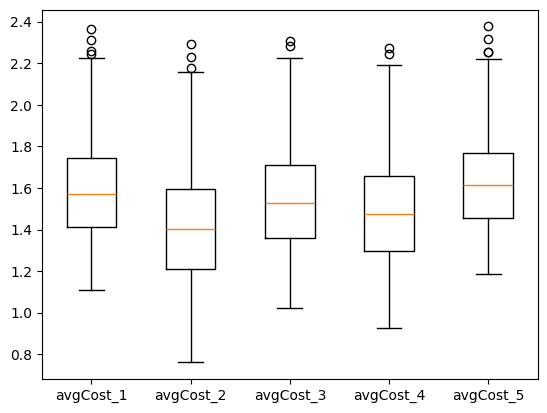

In [32]:
data, labels = [], []
for k in topK:
    data.append(merged_byk[f"avgCost_{k}"])
    labels.append(f"avgCost_{k}")
plt.boxplot(data, labels=labels)
plt.show()

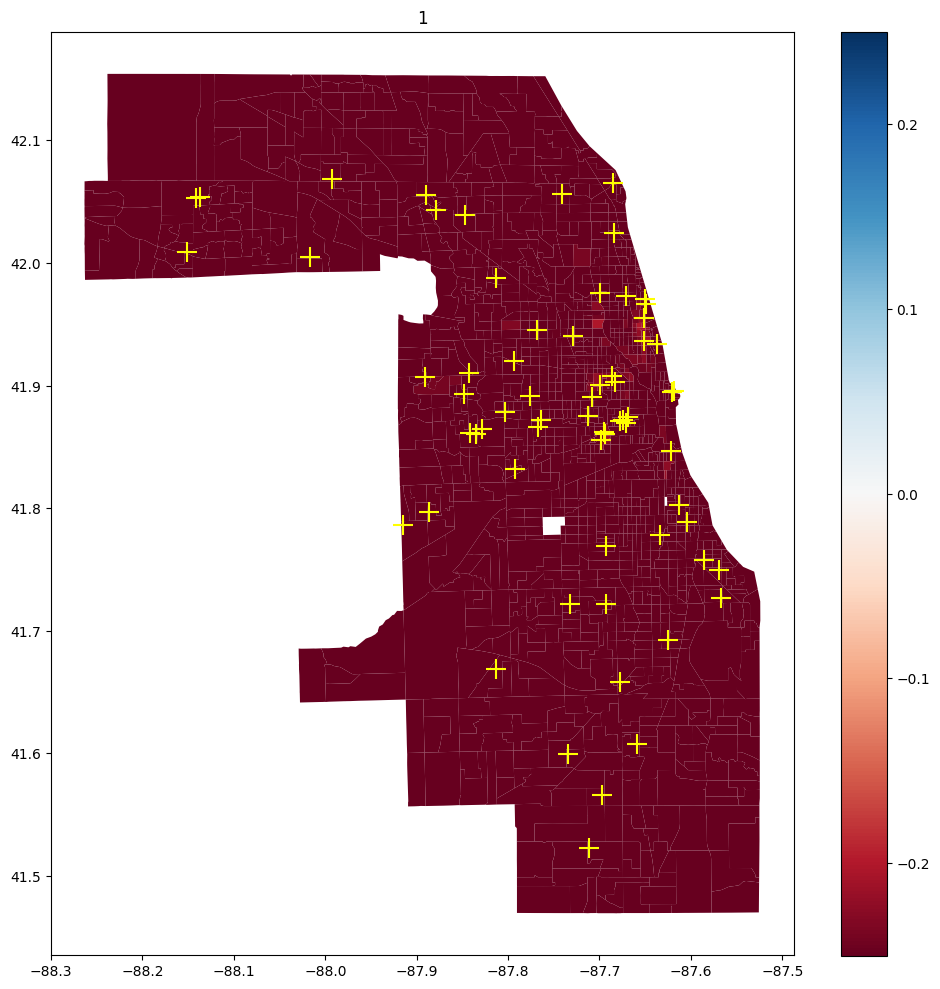

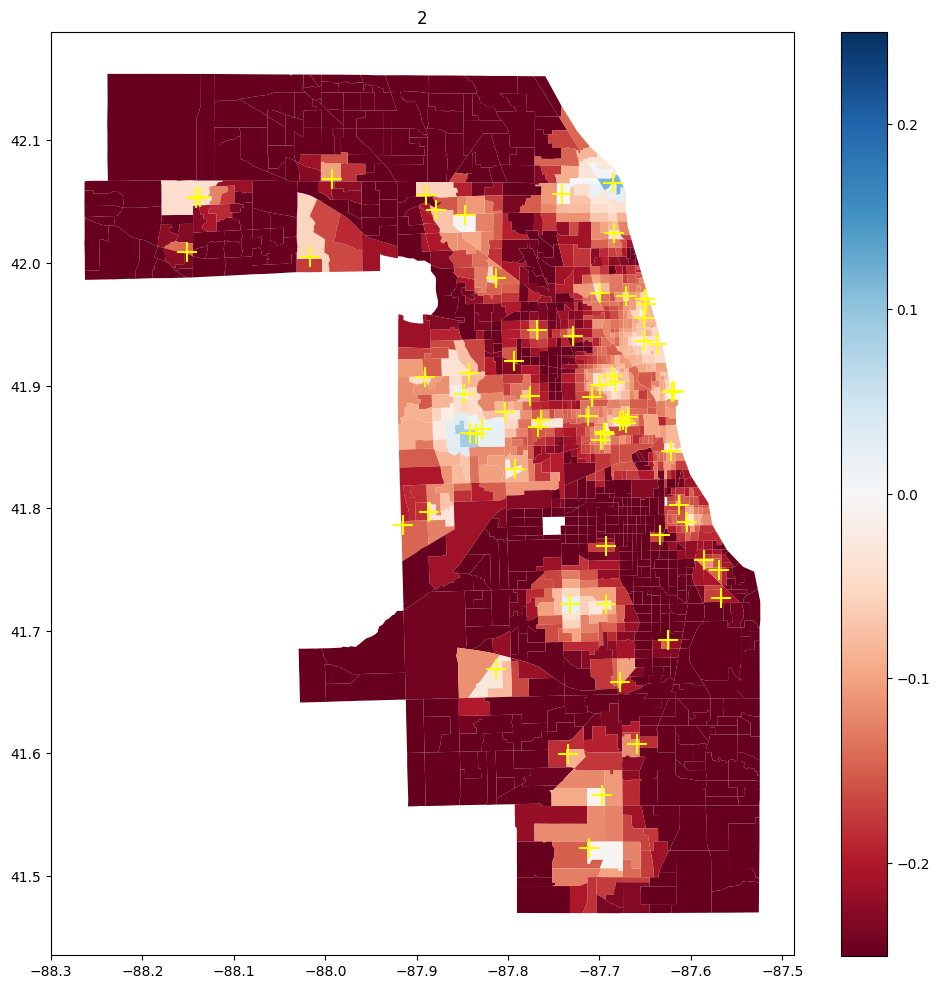

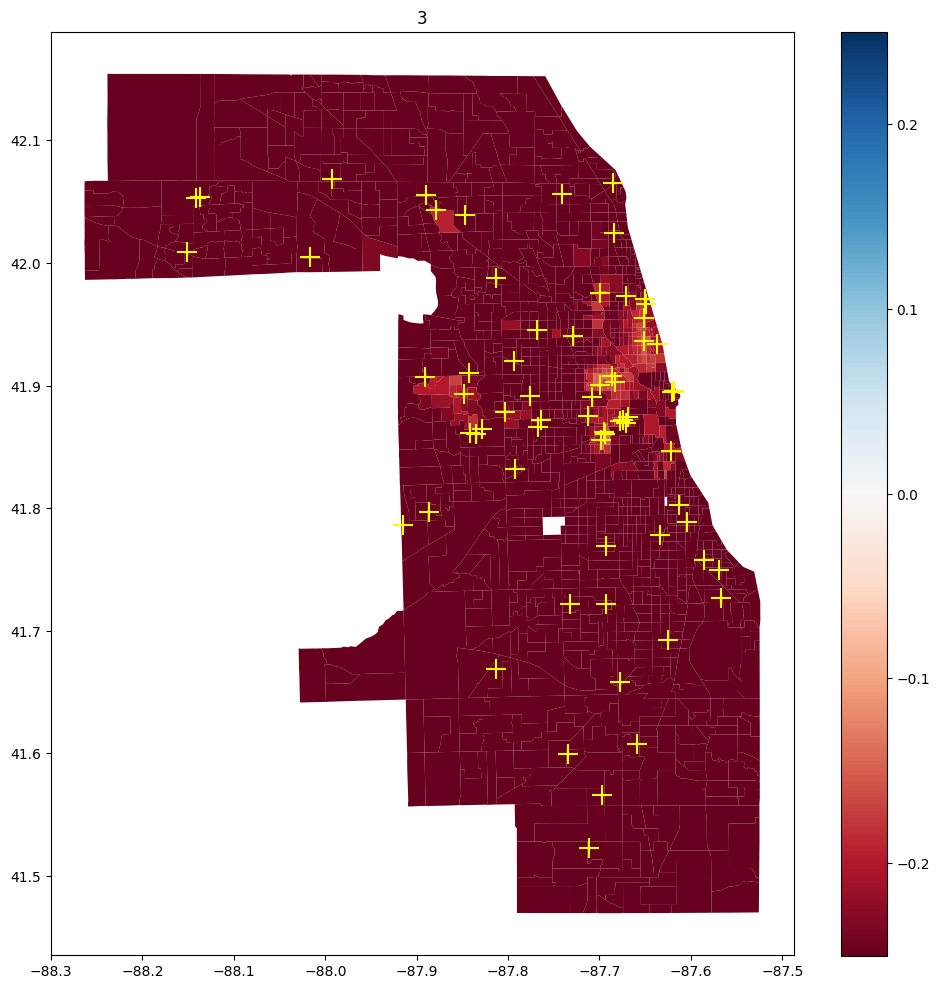

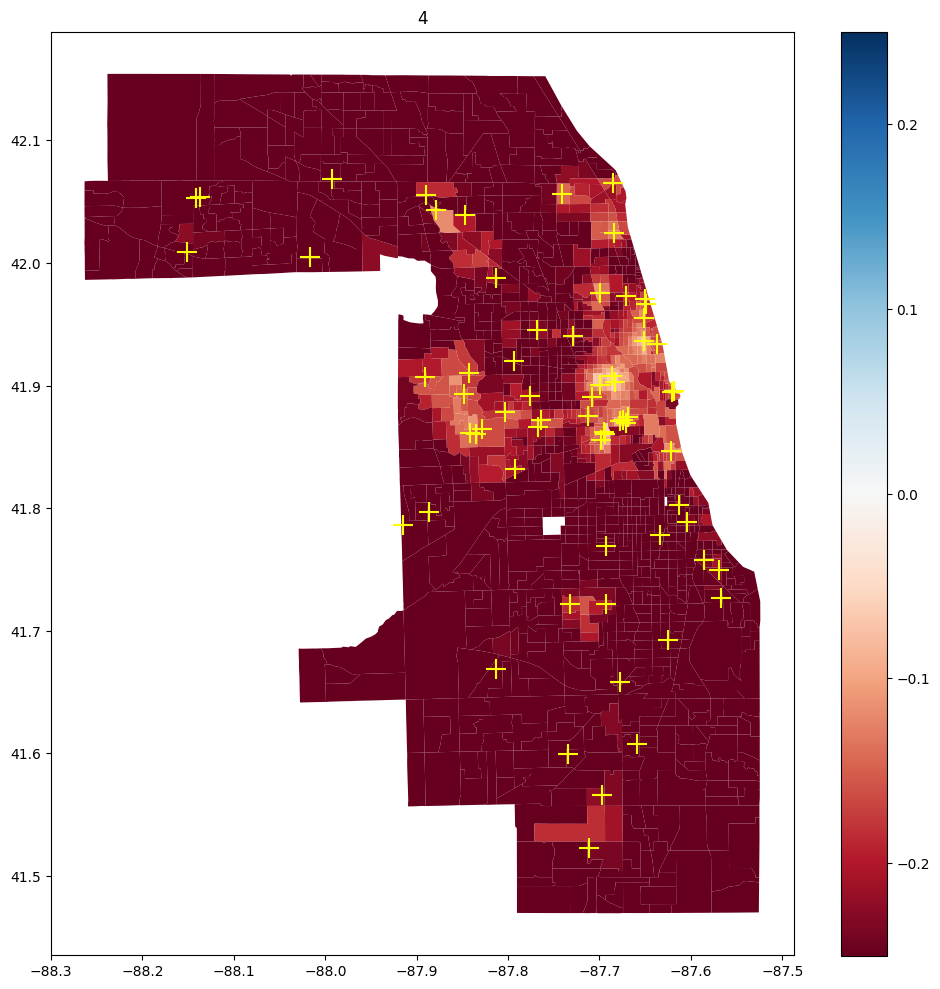

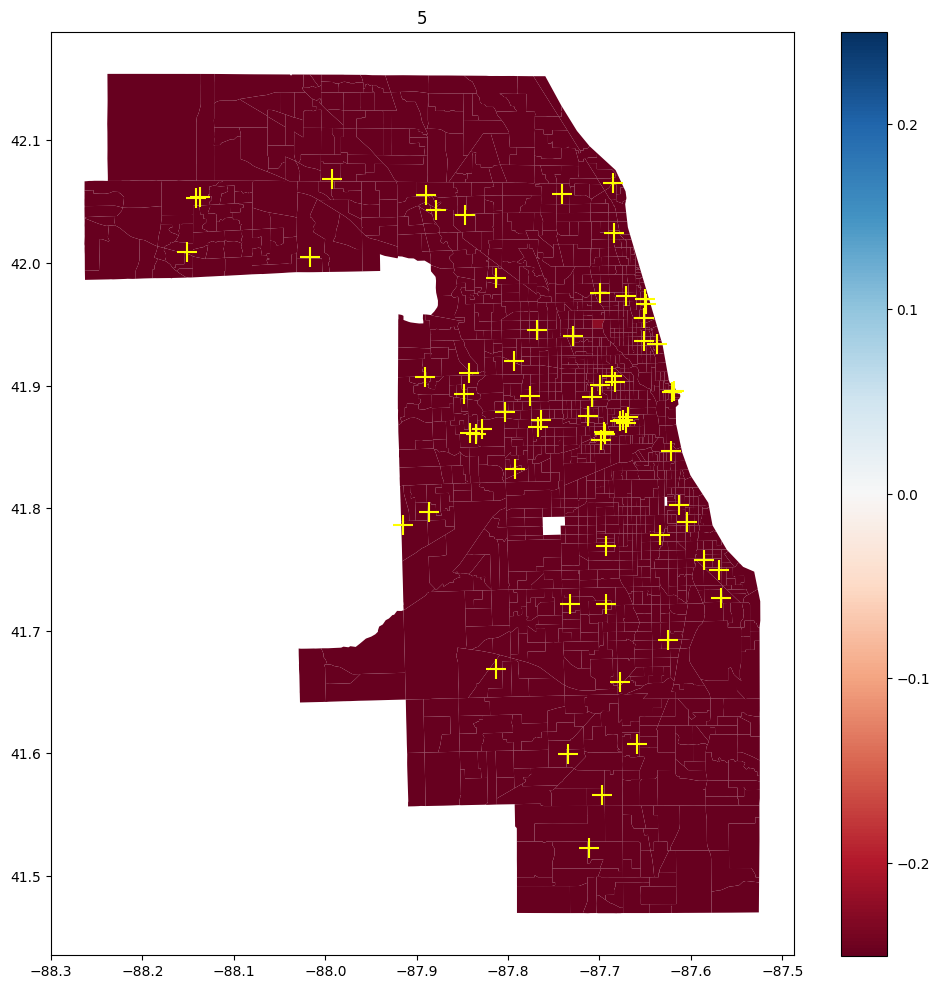

In [33]:
for k in topK:
    merged_byk[f"diff_{k}"] = merged_byk[acc_corr] - merged_byk[f'avgCost_{k}']
    ax = merged_byk.plot(column=f"diff_{k}", figsize=(10, 10), legend=True, cmap="RdBu", vmin=-.25, vmax=.25)
    hos.plot(ax=ax, color='yellow', marker='+', markersize=200)
    # merged.head()
    plt.title(k)
    plt.tight_layout()
    plt.show()

# Mean costs NoVeh vs. OnlyCars

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry
geoid,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019..."
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019..."
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012..."
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.6634 42.0150..."
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009..."


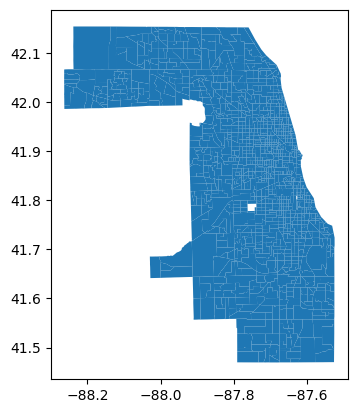

In [34]:
mean_costs_cars = acc.copy(deep=True)
mean_costs_cars.plot()
mean_costs_cars.head()

In [35]:
cost_dict = {x: {'noveh': [], 'onlycars': []} for x in mean_costs.index}
for k, v in experiment_paths.items():
    for path in v:
        # load the parameter json
        param_path = os.path.join(path, "parameters.json")
        param_file = open(param_path)
        params = json.load(param_file)
        cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
        if cf == "raam":
            # load the data
            results = pd.read_csv(os.path.join(path, "spatial_units.csv"), index_col="GEOID")
            results.index = results.index.map(str)
            # drop the ones that don't have population
            results = results[results.index.isin(mean_costs.index)]
            assert max(results[res_col]) < 10
            for index, row in results.iterrows():
                cost_dict[index][k].append(row[res_col])
                    

In [36]:
# list comprehensions can become very dumb
avg_costs_by_cars = {key: [np.mean(ival) for ikey, ival in val.items()] for key, val in cost_dict.items()}

In [37]:
avg_costs_by_cars

{'17031010100': [np.float64(1.4553512573690286),
  np.float64(1.3904969383048715)],
 '17031010201': [np.float64(1.3862891294936712),
  np.float64(1.3457225485713888)],
 '17031010202': [np.float64(1.4443764733631463),
  np.float64(1.415128977289414)],
 '17031010300': [np.float64(1.4908940906268147),
  np.float64(1.4387120839099707)],
 '17031010400': [np.float64(1.5117929662316), np.float64(1.456524724198755)],
 '17031010501': [np.float64(1.592260738547533), np.float64(1.470036595879875)],
 '17031010502': [np.float64(1.5970713672339603),
  np.float64(1.4626971462867187)],
 '17031010503': [np.float64(1.5028134827296133),
  np.float64(1.393202770310979)],
 '17031010600': [np.float64(1.5514516742251576),
  np.float64(1.4459719351887925)],
 '17031010701': [np.float64(1.4143199634687045),
  np.float64(1.3840760817744167)],
 '17031010702': [np.float64(1.4885210624672653),
  np.float64(1.4393565855679358)],
 '17031020100': [np.float64(1.3698253082400216),
  np.float64(1.3365242976787104)],
 '17

In [38]:
avg_costs_by_cars_df = pd.DataFrame.from_dict(avg_costs_by_cars, orient='index', columns=['noveh', 'onlycars'])
avg_costs_by_cars_df.head()

,noveh,onlycars
17031010100,1.455351,1.390497
17031010201,1.386289,1.345723
17031010202,1.444376,1.415129
17031010300,1.490894,1.438712
17031010400,1.511793,1.456525


In [39]:
merged_by_car = acc.merge(avg_costs_by_cars_df, left_index=True, right_index=True)
merged_by_car.head()

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry,noveh,onlycars
geoid,,,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019...",1.455351,1.390497
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019...",1.386289,1.345723
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012...",1.444376,1.415129
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.6634 42.0150...",1.490894,1.438712
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009...",1.511793,1.456525


/tmp/ipykernel_411983/3181800551.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels)


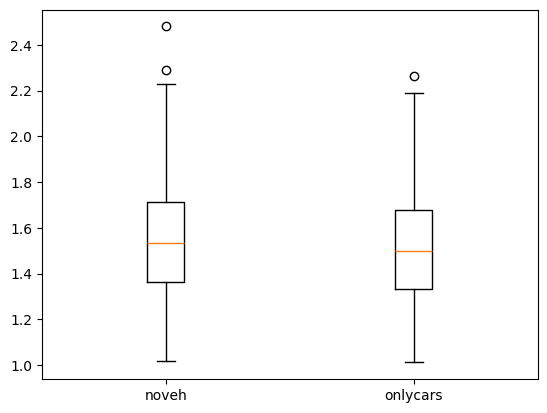

In [40]:
data, labels = [], []
for k in ['noveh', 'onlycars']:
    data.append(merged_by_car[k])
    labels.append(k)
plt.boxplot(data, labels=labels)
plt.show()

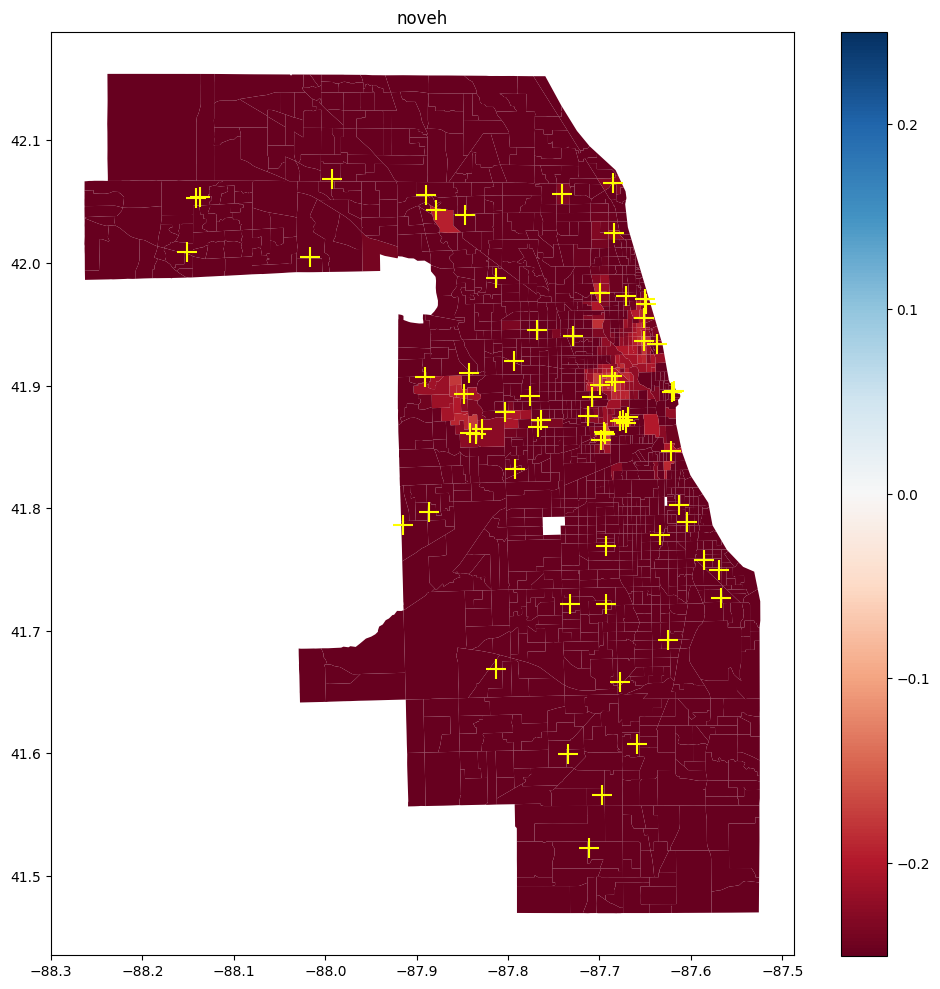

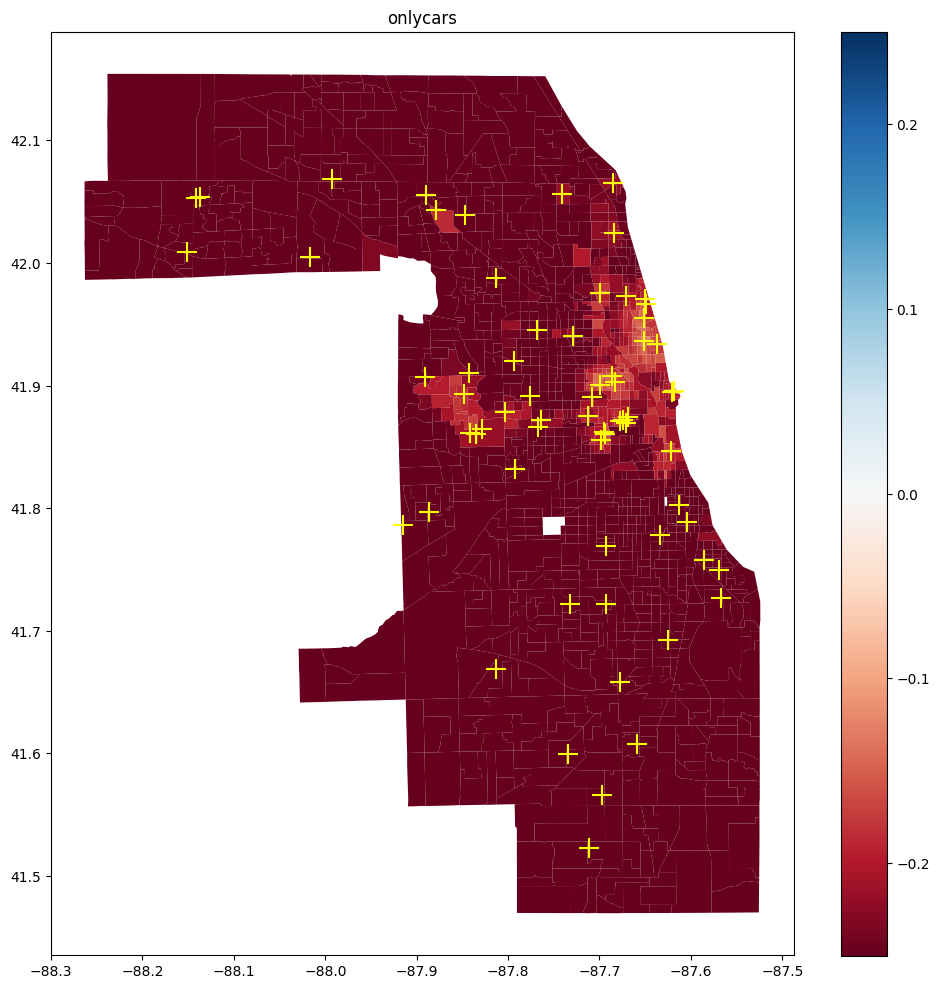

In [41]:
for k in ['noveh', 'onlycars']:
    merged_by_car[f"diff_{k}"] = merged_by_car[acc_corr] - merged_by_car[f'{k}']
    ax = merged_by_car.plot(column=f"diff_{k}", figsize=(10, 10), legend=True, cmap="RdBu", vmin=-.25, vmax=.25)
    hos.plot(ax=ax, color='yellow', marker='+', markersize=200)
    # merged.head()
    plt.title(k)
    plt.tight_layout()
    plt.show()

In [42]:
x = gpd.read_file("../data/svi/SVI2018_US_tract.shp")

In [43]:
x.head()

,ST,STATE,ST_ABBR,STCNTY,COUNTY,FIPS,LOCATION,AREA_SQMI,E_TOTPOP,M_TOTPOP,...,F_THEME4,F_TOTAL,E_UNINSUR,M_UNINSUR,EP_UNINSUR,MP_UNINSUR,E_DAYPOP,Shape_STAr,Shape_STLe,geometry
0,01,ALABAMA,AL,01015,Calhoun,01015981901,"Census Tract 9819.01, Calhoun County, Alabama",24.243865,0,12,...,-999,-999,0,12,-999.0,-999.0,656,0.006105,0.339400,"POLYGON ((-86.01323 33.68426, -86.01224 33.687..."
1,01,ALABAMA,AL,01015,Calhoun,01015981902,"Census Tract 9819.02, Calhoun County, Alabama",34.646714,0,12,...,-999,-999,0,12,-999.0,-999.0,146,0.008752,0.420459,"POLYGON ((-86.0173 33.69662, -86.01704 33.6988..."
2,01,ALABAMA,AL,01015,Calhoun,01015981903,"Census Tract 9819.03, Calhoun County, Alabama",13.926276,0,12,...,-999,-999,0,12,-999.0,-999.0,0,0.003508,0.330164,"POLYGON ((-85.78501 33.66554, -85.78318 33.666..."
3,01,ALABAMA,AL,01097,Mobile,01097003605,"Census Tract 36.05, Mobile County, Alabama",0.732300,899,316,...,-999,-999,33,36,3.7,4.1,5135,0.000180,0.060725,"POLYGON ((-88.1923 30.69524, -88.19097 30.6953..."
4,01,ALABAMA,AL,01097,Mobile,01097990000,"Census Tract 9900, Mobile County, Alabama",0.000000,0,12,...,-999,-999,0,12,-999.0,-999.0,0,0.000536,0.105380,"MULTIPOLYGON (((-88.05337 30.50699, -88.05109 ..."


/home/dijkstra/Documents/GitHubRepos/AgentAccess/venv/lib/python3.12/site-packages/geopandas/geodataframe.py:1819: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


<Axes: >

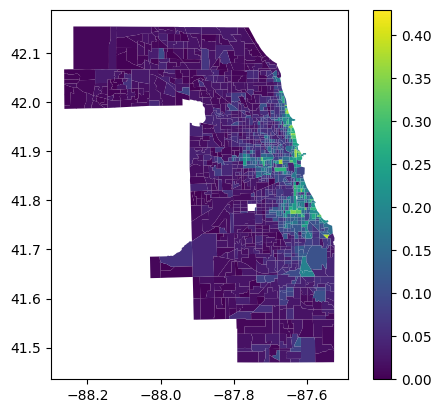

In [44]:
tmp = x[x['STCNTY'] == '17031']
tmp["NOVEHDEN"] = tmp["E_NOVEH"] / tmp["E_TOTPOP"]
tmp.plot('NOVEHDEN', legend=True)

<Axes: >

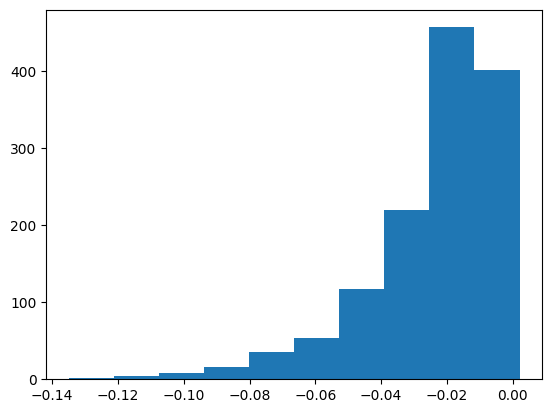

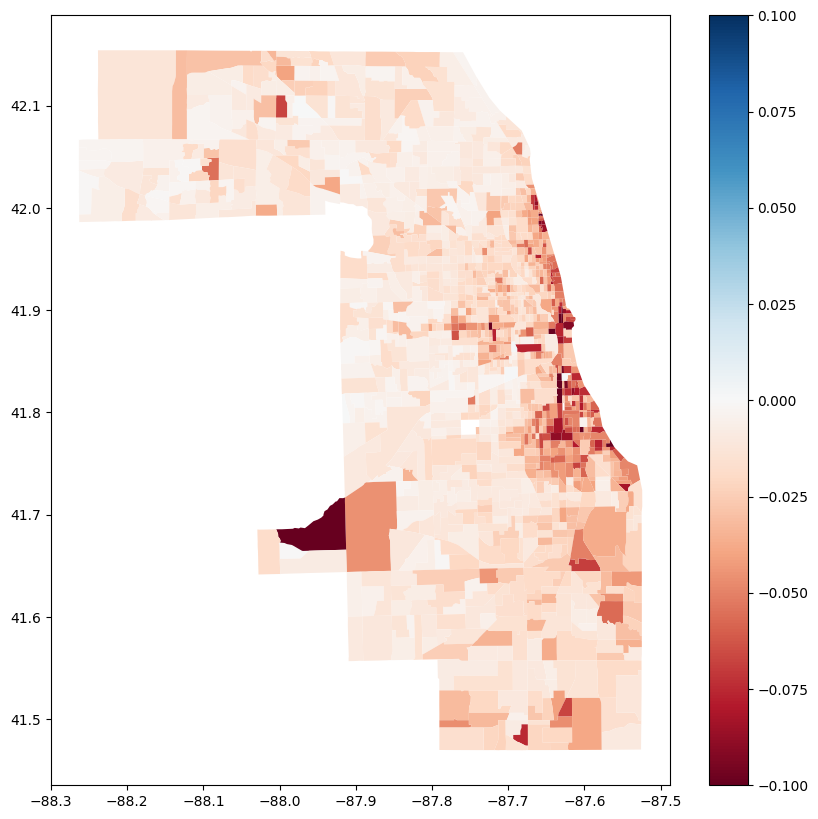

In [45]:
merged_by_car['diffcars'] = (merged_by_car['onlycars'] - merged_by_car['noveh']) / ((merged_by_car['onlycars'] + merged_by_car['noveh']) / 2.0)
plt.hist(merged_by_car['diffcars'])
merged_by_car.plot('diffcars', figsize=(10, 10), legend=True, cmap="RdBu", vmin=-.1, vmax=.1)